# Predicting GSA Labor Rates

**Research Question:** How accurately can a listing's stated requirements and job title predict its hourly ceiling rate on GSA schedule contracts, for vendors the model has not seen?

**Team members:** Maya Dias, Jiei Ota, and Marilyn Ross 

**Repository:** https://github.com/Silverdroplet/project_template

## Setup

In [9]:
from pathlib import Path

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

## Load data

In [17]:
import re

import numpy as np
import pandas as pd

# Date the GSA data was downloaded.
SNAPSHOT_DATE = pd.Timestamp("2026-11-02")

# "None" is a real education level, so only empty strings count as missing.
raw_rates = pd.read_csv(
    DATA_DIR / "gsa_rates_2026-11-02.csv.gz",
    keep_default_na=False,
    na_values=[""],
    low_memory=False,
)
print(f"GSA rates: {raw_rates.shape}")
raw_rates.info()


GSA rates: (351334, 23)
<class 'pandas.DataFrame'>
RangeIndex: 351334 entries, 0 to 351333
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   contract_end          351334 non-null  str    
 1   security_clearance    351334 non-null  bool   
 2   next_year_price       343140 non-null  float64
 3   second_year_price     333903 non-null  float64
 4   vendor_name           351334 non-null  str    
 5   idv_piid              351334 non-null  str    
 6   business_size         351334 non-null  str    
 7   contract_start        351334 non-null  str    
 8   data_source           351334 non-null  str    
 9   labor_category        351334 non-null  str    
 10  schedule              351334 non-null  str    
 11  cont_end_dtg          351334 non-null  int64  
 12  min_years_experience  351334 non-null  int64  
 13  sin                   351334 non-null  str    
 14  worksite              351334 non-null  

## Prepare data

**GSA rates.** Each row is a labor category's ceiling rate on a contract. We drop repeated listings, group education levels, and build features from the title, contract dates, and categories. Vendor names are cleaned into `vendor_key` so spelling variants ("ALTUS LLC", "ALTUS, LLC") stay on one side of the split; it's used only for grouping, not as a feature. Title word features are built inside the models so they learn only from training data.

In [6]:
# Merge similar education levels and combine the rare doctoral ones.
EDUCATION_GROUPS = {
    "None": "None",
    "High School": "High School",
    "High School Equivalent": "High School",
    "Other Tech School or Certification": "Technical",
    "Associates": "Associates",
    "Bachelors": "Bachelors",
    "Masters": "Masters",
    "PhD": "Doctorate",
    "MD DO": "Doctorate",
}
# Lowest to highest, so education keeps its natural order.
EDUCATION_ORDER = ["None", "High School", "Technical", "Associates", "Bachelors", "Masters", "Doctorate"]
# Rows that match on all of these columns are the same listing.
LISTING_KEY = [
    "idv_piid", "labor_category", "education_level", "min_years_experience",
    "worksite", "security_clearance", "current_price",
]
ROMAN_LEVELS = {"i": 1, "ii": 2, "iii": 3, "iv": 4, "v": 5, "vi": 6, "vii": 7, "viii": 8, "ix": 9}
# A level at the end of a title, allowing a closing ")", "]" or "." as in "Engineer (Level 2)".
LEVEL_PATTERN = re.compile(r"\b(?:level\s*)?(ix|viii|vii|vi|iv|v|i{1,3}|[1-9])[\s.)\]]*$")


# Returns the level at the end of a title, or NaN if it has none.
def title_level(title):
    # Try again without a note in parentheses at the end, as in "Accountant II (CPA)".
    for text in (title, re.sub(r"\s*\([^)]*\)$", "", title)):
        match = LEVEL_PATTERN.search(text)
        if match is not None:
            level = match.group(1)
            return int(level) if level.isdigit() else ROMAN_LEVELS[level]
    return np.nan


# The same rate can be listed once per SIN, so keep one row per listing.
rates = raw_rates.drop_duplicates(subset=LISTING_KEY).copy()

rates["title"] = (
    rates["labor_category"].str.lower().str.replace("*", "").str.replace(r"\s+", " ", regex=True).str.strip()
)
# Used only to group the train/test split, not as a feature.
rates["vendor_key"] = (
    rates["vendor_name"].str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\b(?:inc|llc|corp|corporation|co|ltd|lp)\b", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
rates["education"] = pd.Categorical(
    rates["education_level"].map(EDUCATION_GROUPS), categories=EDUCATION_ORDER, ordered=True
)
# Log price is the model target, so effects read as percentages.
rates["log_price"] = np.log(rates["current_price"])
rates["is_small_business"] = rates["business_size"].eq("S")
# Years from the contract start to the download date.
rates["contract_age_years"] = (
    SNAPSHOT_DATE - pd.to_datetime(rates["contract_start"])
).dt.days / 365.25

rates["title_level"] = rates["title"].map(title_level)
# Senior wins if a title has both senior and junior words.
rates["seniority"] = np.select(
    [
        rates["title"].str.contains(r"\b(?:senior|sr|lead|principal|chief)\b"),
        # "data entry" is a job, not a level, so it doesn't count as junior.
        rates["title"].str.contains(r"\b(?:junior|jr|(?<!data )entry|apprentice|intern)\b"),
    ],
    ["senior", "junior"],
    default="unspecified",
)

# A contract can cover several categories, so each one gets its own column.
category_columns = rates["category"].str.get_dummies(sep="; ").astype(bool)
category_columns.columns = "cat_" + category_columns.columns.str.lower().str.replace(r"\W+", "_", regex=True)
rates = pd.concat([rates, category_columns], axis=1)

# Identifiers are kept for reference and grouping, not as features.
ID_COLUMNS = ["id", "idv_piid", "vendor_name", "vendor_key", "labor_category"]
TEXT_COLUMN = "title"
FEATURE_COLUMNS = [
    "education", "min_years_experience", "is_small_business", "worksite",
    "security_clearance", "contract_age_years", "seniority", "title_level",
    *category_columns.columns,
]
TARGET_COLUMNS = ["current_price", "log_price"]
rates = rates[ID_COLUMNS + [TEXT_COLUMN] + FEATURE_COLUMNS + TARGET_COLUMNS].reset_index(drop=True)

assert rates["id"].is_unique
assert rates[TARGET_COLUMNS].notna().all().all()

print(f"Rows: {len(raw_rates):,} raw -> {len(rates):,} after removing repeated listings")
print(
    f"Vendors: {rates['vendor_name'].nunique():,} names -> {rates['vendor_key'].nunique():,} after cleaning, "
    f"contracts: {rates['idv_piid'].nunique():,}"
)
print(f"Titles with a numeric level: {rates['title_level'].notna().mean():.1%}")

Rows: 351,334 raw -> 327,634 after removing repeated listings
Vendors: 6,645 names -> 6,635 after cleaning, contracts: 6,773
Titles with a numeric level: 47.2%


In [18]:
rates.info()


<class 'pandas.DataFrame'>
RangeIndex: 327634 entries, 0 to 327633
Data columns (total 28 columns):
 #   Column                                     Non-Null Count   Dtype   
---  ------                                     --------------   -----   
 0   id                                         327634 non-null  int64   
 1   idv_piid                                   327634 non-null  str     
 2   vendor_name                                327634 non-null  str     
 3   vendor_key                                 327634 non-null  str     
 4   labor_category                             327634 non-null  str     
 5   title                                      327634 non-null  str     
 6   education                                  327634 non-null  category
 7   min_years_experience                       327634 non-null  int64   
 8   is_small_business                          327634 non-null  bool    
 9   worksite                                   327634 non-null  str     
 10  securit

In [19]:
#looks at a few rows of the new prepared data set

print(f"GSA rates: {raw_rates.shape}")
rates.head(50)



GSA rates: (351334, 23)


,id,idv_piid,vendor_name,vendor_key,labor_category,title,education,min_years_experience,is_small_business,worksite,...,cat_information_technology,cat_miscellaneous,cat_office_management,cat_professional_services,cat_scientific_management_and_solutions,cat_security_and_protection,cat_transportation_and_logistics_services,cat_travel,current_price,log_price
0,1784019177,GS02F0022W,"MANAGEMENT RECRUITERS OF FORT WORTH-SW, L.P.",management recruiters of fort worthsw,Customer Support,customer support,High School,1,True,Customer_Facility,...,False,True,True,False,False,False,False,False,20.1000,3.000720
1,1746309816,47QTCA22D007R,"ANYTHINGIT, LLC.",anythingit,Assets Project Management,assets project management,None,0,True,Customer_Facility,...,True,True,True,False,False,False,False,False,20.1500,3.003204
2,1746309820,47QTCA22D007R,"ANYTHINGIT, LLC.",anythingit,Asset Tagging Service,asset tagging service,None,0,True,Customer_Facility,...,True,True,True,False,False,False,False,False,20.1500,3.003204
3,1318669414,47QRAA20D006N,"TECHNOLOGY, AUTOMATION & MANAGEMENT, INC.",technology automation management,Inpatient encouner Medical Coding Auditor,inpatient encouner medical coding auditor,High School,3,True,Contractor_Facility,...,True,True,False,True,False,False,False,False,20.1725,3.004320
4,1757976848,47QRAA26D007Z,PROVIDENCE STAFFING LLC,providence staffing,Janitor**,janitor,High School,1,True,Customer_Facility,...,False,True,True,False,False,False,False,False,20.2400,3.007661
5,1757976847,47QRAA26D007Z,PROVIDENCE STAFFING LLC,providence staffing,Cafeteria Worker**,cafeteria worker,High School,1,True,Customer_Facility,...,False,True,True,False,False,False,False,False,20.2400,3.007661
6,1173453301,GS21F0049X,SOURCEAMERICA,sourceamerica,Supervisor I,supervisor i,High School,3,False,Customer_Facility,...,False,True,True,True,False,False,False,False,20.2800,3.009635
7,1731191204,47QRAA15D0002,ITSQUEST INC,itsquest,Food Service Worker,food service worker,High School,0,True,Customer_Facility,...,False,True,True,False,False,False,False,False,20.2900,3.010128
8,1482014044,47QRAA25D007N,FRIEMAN KHATRI & PARTNERS LLC,frieman khatri partners,General Clerk,general clerk,High School,1,True,Customer_Facility,...,False,True,True,True,False,False,False,False,20.3200,3.011606
9,1710487822,47QRAA22D004N,"T47 INTERNATIONAL, INC.",t47 international,Guard II,guard ii,High School,1,True,Customer_Facility,...,False,True,False,True,False,True,False,False,20.3800,3.014554


## Explore data

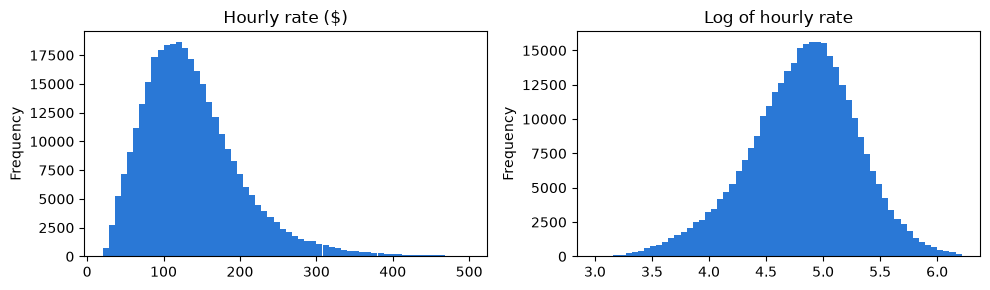

Skewness: rate 1.21, log rate -0.31
Rate range: $20.10 to $500.00; next-year rates above $500: 92


In [58]:
import matplotlib.pyplot as plt

RATE_COLOR = "#2a78d6"

# Figure 1: hourly rates, and their logs.
fig, (ax_raw, ax_log) = plt.subplots(1, 2, figsize=(10, 3))
rates["current_price"].plot.hist(bins=60, ax=ax_raw, color=RATE_COLOR, title="Hourly rate ($)")
rates["log_price"].plot.hist(bins=60, ax=ax_log, color=RATE_COLOR, title="Log of hourly rate")
plt.tight_layout()
plt.show()

print(f"Skewness: rate {rates['current_price'].skew():.2f}, log rate {rates['log_price'].skew():.2f}")
# The file appears to be cut off at $500: no current rate is above it, but some next-year rates are.
next_year = pd.to_numeric(raw_rates["next_year_price"], errors="coerce")
print(
    f"Rate range: ${rates['current_price'].min():.2f} to ${rates['current_price'].max():.2f}; "
    f"next-year rates above $500: {(next_year > 500).sum()}"
)

**Rates are skewed.** The middle half falls between $92 and $171, with a tail to $500 (skewness 1.21). Log rate is nearly symmetric (−0.31), so the models predict log rate and errors read as percentages.

**Rates are limited to $20–$500.** No current rate is above $500.00, yet 92 next-year rates are, so the file appears to have been filtered on current rate. The models only cover rates in this range.

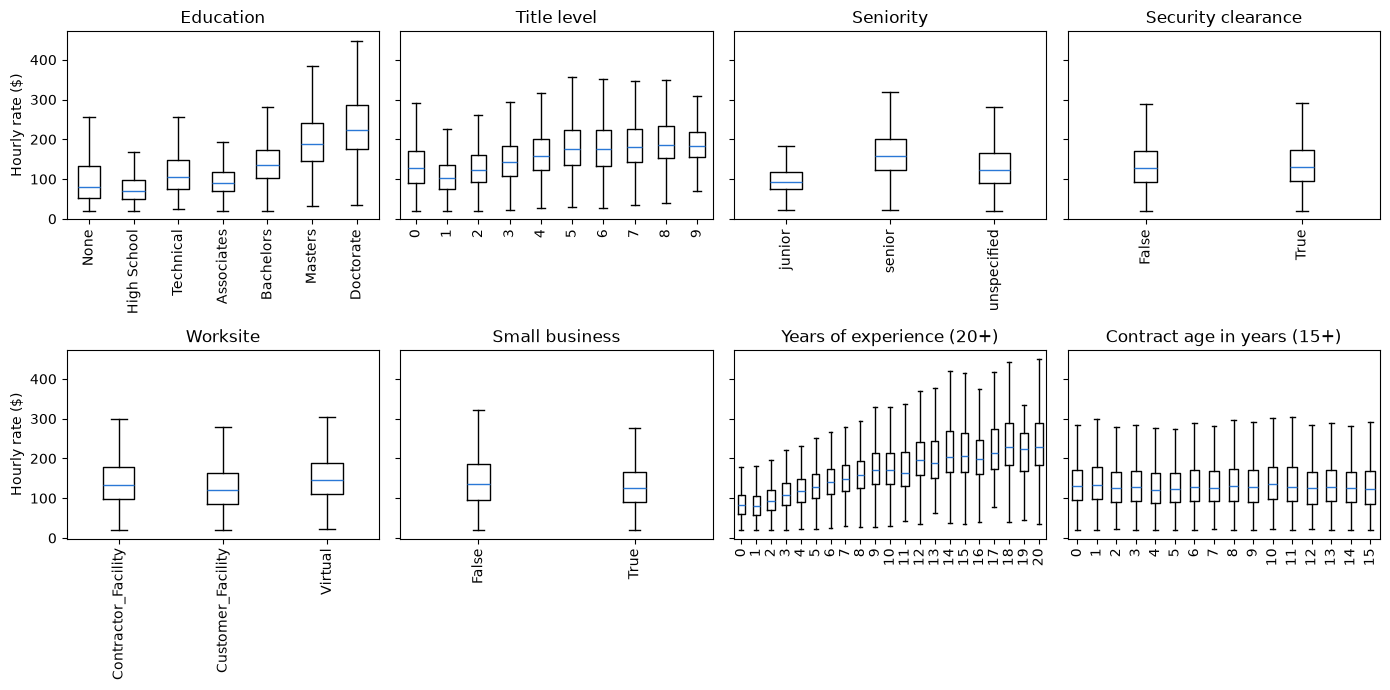

In [59]:
# Figure 2: hourly rate by each predictor, without outliers. A title level of 0 means the title has none.
PREDICTORS = {
    "Education": rates["education"],
    "Title level": rates["title_level"].fillna(0).astype(int),
    "Seniority": rates["seniority"],
    "Security clearance": rates["security_clearance"],
    "Worksite": rates["worksite"],
    "Small business": rates["is_small_business"],
    "Years of experience (20+)": rates["min_years_experience"].clip(upper=20),
    "Contract age in years (15+)": rates["contract_age_years"].astype(int).clip(upper=15),
}
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=True)
for ax, (name, groups) in zip(axes.flat, PREDICTORS.items()):
    labels, prices = zip(*rates.groupby(groups, observed=True)["current_price"])
    ax.boxplot(prices, tick_labels=labels, showfliers=False, medianprops={"color": RATE_COLOR})
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=90)
for ax in axes[:, 0]:
    ax.set_ylabel("Hourly rate ($)")
plt.tight_layout()
plt.show()

**Rates by predictor.** Education, seniority, title level, and experience show the clearest steps: the median rate rises from $135 (bachelor's) to $222 (doctorate), $93 (junior) to $157 (senior), and ~$80 (0–1 years) to ~$200 (12+ years). Contractor-site and virtual work cost more than government-site work, and small businesses charge slightly less. Clearance and contract age show little difference alone but stay in the models in case they matter once other predictors are held fixed.

In [60]:
# Vendors: how much of the variation in log rate lies between them.
between_vendor_share = rates.groupby("vendor_key")["log_price"].transform("mean").var() / rates["log_price"].var()
print(f"Variation in log rate between vendors: {between_vendor_share:.0%}")

# Titles: whole titles are rarely shared between vendors, but the words in them are.
title_vendors = rates.groupby("title")["vendor_key"].nunique()
words = rates[["vendor_key"]].assign(word=rates["title"].str.findall(r"[a-z]+")).explode("word").dropna()
word_vendors = words.groupby("word")["vendor_key"].nunique()
print(f"Distinct titles: {len(title_vendors):,}; used by only one vendor: {(title_vendors == 1).mean():.0%}")
print(f"Words in titles used by at least 5 vendors: {words['word'].map(word_vendors).ge(5).mean():.0%}")

# Missing values, and features that are almost always the same value.
most_common_share = rates[FEATURE_COLUMNS].apply(lambda column: column.value_counts(normalize=True).iloc[0])
print(f"Title level missing: {rates['title_level'].isna().mean():.0%}")
print("Features with one value in at least 99% of rows:", list(most_common_share[most_common_share >= 0.99].index))

Variation in log rate between vendors: 38%
Distinct titles: 128,242; used by only one vendor: 84%
Words in titles used by at least 5 vendors: 97%
Title level missing: 53%
Features with one value in at least 99% of rows: ['cat_industrial_products_and_services', 'cat_miscellaneous', 'cat_transportation_and_logistics_services', 'cat_travel']


**Why split by vendor and use title words.** 38% of log-rate variation lies between vendors, so the split and cross-validation are grouped by `vendor_key` to keep models from scoring well by learning known vendors' pricing. Whole titles don't transfer (84% of 128,242 titles belong to one vendor), but their words do (97% are used by 5+ vendors). Title level is blank for 53% of listings, so the models need a "no level" group, and four category columns are constant in ≥99% of rows, so they add almost nothing.

## Build models

In [20]:
# Train baseline and candidate models.
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

X = rates[FEATURE_COLUMNS + [TEXT_COLUMN]]
y = rates["log_price"]

train_idx, test_idx = next(
    GroupShuffleSplit(test_size=0.2, random_state=42).split(X, y, groups=rates["vendor_key"])
)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

#always predict the mean log rate of the training set.
baseline_pred = DummyRegressor().fit(X_train, y_train).predict(X_test)
print(
    f"Baseline RMSE: {np.sqrt(mean_squared_error(y_test, baseline_pred)):.3f}, "
    f"R2: {r2_score(y_test, baseline_pred):.3f}"
)

X_train shape: (265749, 21) | X_test shape: (61885, 21)
Baseline RMSE: 0.475, R2: -0.001


In [ ]:
# LInear regression
# k cluster
 #years of experience and education levels
#random forest

## Evaluate models

In [ ]:
# Compare models using the chosen evaluation measures.


## Final results

In [63]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]